# Tugas Lab 2 - Exact NN vs ANNOY vs FAISS vs HNSW (Spotify)

In [10]:
import warnings
warnings.filterwarnings("ignore", message="IProgress not found")

import gc
import time
from pathlib import Path

import kagglehub
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import faiss
import hnswlib
from annoy import AnnoyIndex
from sklearn.neighbors import NearestNeighbors
from sklearn.preprocessing import StandardScaler

FEATURES = [
    "danceability", "energy", "loudness", "speechiness",
    "acousticness", "instrumentalness", "liveness", "valence", "tempo",
]
K = 10
QUERY_IDX = 0
N_TREES = 20
EF_CONSTRUCTION = 200
M = 16
EF_SEARCH = 50
SEED = 42

np.random.seed(SEED)
print("ready")

ready


In [11]:
# Download latest version via kagglehub
path = kagglehub.dataset_download("bwandowando/spotify-songs-with-attributes-and-lyrics")
print("Path to dataset files:", path)

data_dir = Path(path)
csv_candidates = sorted(data_dir.rglob("songs_with_attributes_and_lyrics.csv"))
if not csv_candidates:
    csv_candidates = sorted(data_dir.rglob("*.csv"))
if not csv_candidates:
    raise FileNotFoundError(f"CSV tidak ditemukan di {data_dir}")

csv_path = csv_candidates[0]
data_source = "Kaggle - bwandowando/spotify-songs-with-attributes-and-lyrics"
print("pakai:", csv_path)

Path to dataset files: C:\Users\laksa\.cache\kagglehub\datasets\bwandowando\spotify-songs-with-attributes-and-lyrics\versions\20
pakai: C:\Users\laksa\.cache\kagglehub\datasets\bwandowando\spotify-songs-with-attributes-and-lyrics\versions\20\songs_with_attributes_and_lyrics.csv


## Load + pilih fitur numerik + StandardScaler

In [12]:
# skip kolom lyrics biar load lebih ringan (~1.5GB penuh)
header = pd.read_csv(csv_path, nrows=0)
usecols = [c for c in header.columns if c.lower() != "lyrics"]
df_raw = pd.read_csv(csv_path, usecols=usecols)
print("shape mentah:", df_raw.shape)
print("kolom:", list(df_raw.columns))
print("data_source:", data_source)

missing = [f for f in FEATURES if f not in df_raw.columns]
if missing:
    raise ValueError(f"kolom fitur kurang: {missing}. Cek CSV-nya.")

# dropna di fitur
df = df_raw.dropna(subset=FEATURES).copy()

# track yang sama bisa muncul berkali. dedupe biar NN ga ketemu 'diri sendiri'
id_col = next((c for c in ("track_id", "id") if c in df.columns), None)
n_before = len(df)
if id_col:
    df = df.drop_duplicates(subset=[id_col], keep="first").reset_index(drop=True)
    print(f"dedupe {id_col}: {n_before} -> {len(df)}")
else:
    df = df.reset_index(drop=True)
    print("ga ada id/track_id, skip dedupe. rows=", len(df))

X = df[FEATURES].values.astype(np.float32)
X_scaled = StandardScaler().fit_transform(X).astype(np.float32)
n, dim = X_scaled.shape
print(f"n={n}, dim={dim}")

# label buat nampilin hasil
name_col = "track_name" if "track_name" in df.columns else ("name" if "name" in df.columns else None)
artist_col = next((c for c in ("artists", "track_artist", "artist") if c in df.columns), None)

def track_label(i):
    parts = []
    if name_col:
        parts.append(str(df.iloc[i][name_col]))
    if artist_col:
        parts.append(str(df.iloc[i][artist_col]))
    return " — ".join(parts) if parts else f"idx={i}"

query = X_scaled[QUERY_IDX:QUERY_IDX+1]
print("query:", track_label(QUERY_IDX))

shape mentah: (955320, 16)
kolom: ['id', 'name', 'album_name', 'artists', 'danceability', 'energy', 'key', 'loudness', 'mode', 'speechiness', 'acousticness', 'instrumentalness', 'liveness', 'valence', 'tempo', 'duration_ms']
data_source: Kaggle - bwandowando/spotify-songs-with-attributes-and-lyrics
dedupe id: 955320 -> 955320
n=955320, dim=9
query: ! — HELLYEAH


## Bangun index + cari k-NN

Bandingin Exact NN (sklearn brute), ANNOY, FAISS (IndexFlatL2), HNSW. Waktu build & query dipisah.

In [13]:
results = {}  # name -> dict

# Exact NN
nn = NearestNeighbors(n_neighbors=K + 1, algorithm="brute", metric="euclidean")
t0 = time.perf_counter()
nn.fit(X_scaled)
build_e = time.perf_counter() - t0

t0 = time.perf_counter()
dist_e, idx_e = nn.kneighbors(query)
query_e = time.perf_counter() - t0
idx_e = [int(i) for i in idx_e[0] if int(i) != QUERY_IDX][:K]
results["Exact NN"] = {"build": build_e, "query": query_e, "idx": idx_e, "dist": dist_e[0][1:K+1]}

# ANNOY
ann = AnnoyIndex(dim, "euclidean")
t0 = time.perf_counter()
for i in range(n):
    ann.add_item(i, X_scaled[i])
ann.build(N_TREES)
build_a = time.perf_counter() - t0

t0 = time.perf_counter()
idx_a = ann.get_nns_by_vector(query[0], K + 1, include_distances=True)
query_a = time.perf_counter() - t0
# idx_a = (ids, dists)
ids_a = [i for i in idx_a[0] if i != QUERY_IDX][:K]
results["ANNOY"] = {"build": build_a, "query": query_a, "idx": ids_a}

# FAISS Flat L2 (exact brute force di FAISS)
index_f = faiss.IndexFlatL2(dim)
t0 = time.perf_counter()
index_f.add(X_scaled)
build_f = time.perf_counter() - t0

t0 = time.perf_counter()
D_f, I_f = index_f.search(query, K + 1)
query_f = time.perf_counter() - t0
idx_f = [int(i) for i in I_f[0] if int(i) != QUERY_IDX][:K]
results["FAISS"] = {"build": build_f, "query": query_f, "idx": idx_f}

# HNSW
hnsw = hnswlib.Index(space="l2", dim=dim)
t0 = time.perf_counter()
hnsw.init_index(max_elements=n, ef_construction=EF_CONSTRUCTION, M=M)
hnsw.add_items(X_scaled)
build_h = time.perf_counter() - t0
hnsw.set_ef(EF_SEARCH)

t0 = time.perf_counter()
labels_h, dists_h = hnsw.knn_query(query, k=K + 1)
query_h = time.perf_counter() - t0
idx_h = [int(i) for i in labels_h[0] if int(i) != QUERY_IDX][:K]
results["HNSW"] = {"build": build_h, "query": query_h, "idx": idx_h}

for name, r in results.items():
    print(f"{name:10s} build={r['build']*1000:8.1f} ms  query={r['query']*1000:8.3f} ms")

Exact NN   build=    23.9 ms  query=  13.300 ms
ANNOY      build=  8256.0 ms  query=   0.261 ms
FAISS      build=    25.2 ms  query=   7.236 ms
HNSW       build= 20975.3 ms  query=   0.518 ms


## Tabel performansi + recall vs Exact

In [14]:
exact_set = set(results["Exact NN"]["idx"])

rows = []
for name, r in results.items():
    recall = len(exact_set & set(r["idx"])) / K
    rows.append({
        "Metode": name,
        "Build (ms)": r["build"] * 1000,
        "Query (ms)": r["query"] * 1000,
        "Total (ms)": (r["build"] + r["query"]) * 1000,
        "Recall@10 vs Exact": recall,
        "Top-3": "; ".join(track_label(i) for i in r["idx"][:3]),
    })

perf = pd.DataFrame(rows)
perf

,Metode,Build (ms),Query (ms),Total (ms),Recall@10 vs Exact,Top-3
0,Exact NN,23.8590,13.2998,37.1588,1.0,Intro (Who The Fuck Are You') — C-Lekktor; Tes...
1,ANNOY,8256.0365,0.2614,8256.2979,1.0,Intro (Who The Fuck Are You') — C-Lekktor; Tes...
2,FAISS,25.2048,7.2358,32.4406,1.0,Intro (Who The Fuck Are You') — C-Lekktor; Tes...
3,HNSW,20975.2805,0.5180,20975.7985,1.0,Intro (Who The Fuck Are You') — C-Lekktor; Tes...


## 10 tetangga terdekat per metode

In [15]:
neighbor_rows = []
for name, r in results.items():
    for rank, i in enumerate(r["idx"], 1):
        neighbor_rows.append({
            "Metode": name,
            "Rank": rank,
            "idx": i,
            "Track": track_label(i),
        })

neighbors_df = pd.DataFrame(neighbor_rows)
# tampilkan per metode
for name in results:
    print(f"\n=== {name} ===")
    sub = neighbors_df[neighbors_df["Metode"] == name][["Rank", "Track"]]
    display(sub)


=== Exact NN ===


,Rank,Track
0,1,Intro (Who The Fuck Are You') — C-Lekktor
1,2,Testimonium — Lacrimosa
2,3,Ultimate Satisfaction - The Field Remix — Bear...
3,4,Sæglópur — Sigur Rós
4,5,Autumn Interlude — Amethystium
5,6,Púrpura — Margaritas Podridas
6,7,Turn from Heaven — Therion
7,8,See You When I Die — BOYO
8,9,Mrityu — Multani;Karun;Udbhav
9,10,Bewitched — The Wedding Present



=== ANNOY ===


,Rank,Track
10,1,Intro (Who The Fuck Are You') — C-Lekktor
11,2,Testimonium — Lacrimosa
12,3,Ultimate Satisfaction - The Field Remix — Bear...
13,4,Sæglópur — Sigur Rós
14,5,Autumn Interlude — Amethystium
15,6,Púrpura — Margaritas Podridas
16,7,Turn from Heaven — Therion
17,8,See You When I Die — BOYO
18,9,Mrityu — Multani;Karun;Udbhav
19,10,Bewitched — The Wedding Present



=== FAISS ===


,Rank,Track
20,1,Intro (Who The Fuck Are You') — C-Lekktor
21,2,Testimonium — Lacrimosa
22,3,Ultimate Satisfaction - The Field Remix — Bear...
23,4,Sæglópur — Sigur Rós
24,5,Autumn Interlude — Amethystium
25,6,Púrpura — Margaritas Podridas
26,7,Turn from Heaven — Therion
27,8,See You When I Die — BOYO
28,9,Mrityu — Multani;Karun;Udbhav
29,10,Bewitched — The Wedding Present



=== HNSW ===


,Rank,Track
30,1,Intro (Who The Fuck Are You') — C-Lekktor
31,2,Testimonium — Lacrimosa
32,3,Ultimate Satisfaction - The Field Remix — Bear...
33,4,Sæglópur — Sigur Rós
34,5,Autumn Interlude — Amethystium
35,6,Púrpura — Margaritas Podridas
36,7,Turn from Heaven — Therion
37,8,See You When I Die — BOYO
38,9,Mrityu — Multani;Karun;Udbhav
39,10,Bewitched — The Wedding Present


## Visualisasi waktu

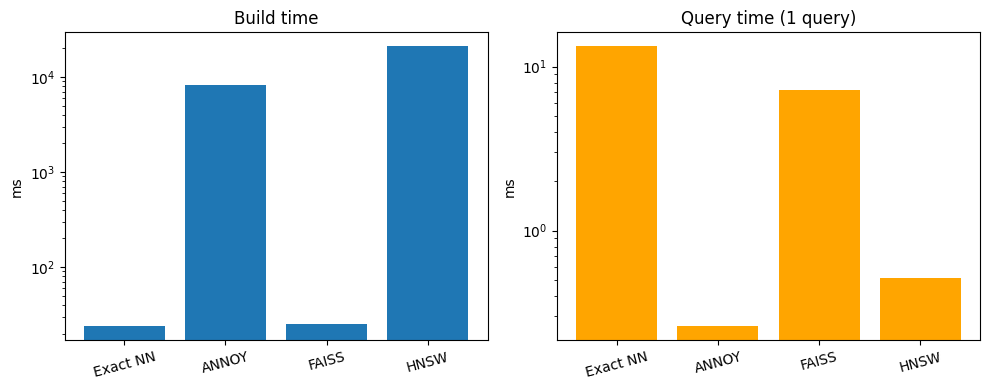

  Metode  Build (ms)  Query (ms)  Recall@10 vs Exact
Exact NN     23.8590     13.2998                 1.0
   ANNOY   8256.0365      0.2614                 1.0
   FAISS     25.2048      7.2358                 1.0
    HNSW  20975.2805      0.5180                 1.0


In [16]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
methods = list(perf["Metode"])
x = np.arange(len(methods))

axes[0].bar(x, perf["Build (ms)"])
axes[0].set_xticks(x)
axes[0].set_xticklabels(methods, rotation=15)
axes[0].set_ylabel("ms")
axes[0].set_title("Build time")
axes[0].set_yscale("log")

axes[1].bar(x, perf["Query (ms)"], color="orange")
axes[1].set_xticks(x)
axes[1].set_xticklabels(methods, rotation=15)
axes[1].set_ylabel("ms")
axes[1].set_title("Query time (1 query)")
axes[1].set_yscale("log")

plt.tight_layout()
plt.show()

print(perf[["Metode", "Build (ms)", "Query (ms)", "Recall@10 vs Exact"]].to_string(index=False))

In [17]:
# ringkas angka run ini
print(f"Dataset rows dipakai: {n}, dim={dim}")
print(f"Query track: {track_label(QUERY_IDX)}")
print(f"Provenance note: {data_source}")
print()

# FAISS Flat harusnya recall 1.0 vs Exact
print("Recall:")
for _, row in perf.iterrows():
    print(f"  {row['Metode']}: {row['Recall@10 vs Exact']:.2f}")

print()
fast_q = perf.loc[perf["Query (ms)"].idxmin(), "Metode"]
slow_b = perf.loc[perf["Build (ms)"].idxmax(), "Metode"]
print(f"Query paling cepet: {fast_q}")
print(f"Build paling lama: {slow_b}")

# overlap urutan exact vs approx
for name in ["ANNOY", "FAISS", "HNSW"]:
    same_order = results[name]["idx"] == results["Exact NN"]["idx"]
    print(f"{name} urutan sama persis dgn Exact? {same_order}")

Dataset rows dipakai: 955320, dim=9
Query track: ! — HELLYEAH
Provenance note: Kaggle - bwandowando/spotify-songs-with-attributes-and-lyrics

Recall:
  Exact NN: 1.00
  ANNOY: 1.00
  FAISS: 1.00
  HNSW: 1.00

Query paling cepet: ANNOY
Build paling lama: HNSW
ANNOY urutan sama persis dgn Exact? True
FAISS urutan sama persis dgn Exact? True
HNSW urutan sama persis dgn Exact? True


## Kesimpulan

Membandingkan Exact NN (sklearn brute), ANNOY, FAISS `IndexFlatL2`, sama HNSW buat nyari 10 lagu terdekat dari fitur audio Spotify. Datasetnya ~955k lagu, 9 fitur (`danceability`, `energy`, dll) yang udah di-`StandardScaler`.

Hasil run-nya kurang lebih :

| Metode | Build | Query (1x) | Recall@10 |
|--------|------:|-----------:|----------:|
| Exact NN | ~24 ms | ~13.3 ms | 1.0 |
| ANNOY | ~8.3 s | ~0.26 ms | 1.0 |
| FAISS Flat | ~25 ms | ~7.2 ms | 1.0 |
| HNSW | ~21 s | ~0.52 ms | 1.0 |

Yang paling kelihatan: **query ANNOY/HNSW jauh lebih cepet** dibanding Exact NN, tapi bayarannya di **waktu build**. HNSW paling lama ngebangun index (~21 detik), ANNOY sekitar 8 detik. Exact NN sama FAISS Flat hampir ga ngebangun apa-apa (cuma nyimpen data), makanya build-nya kilat.

fAISS di sini pakai `IndexFlatL2`, jadi ini **exact search** juga, bukan ANN. Bedanya sama sklearn cuma implementasinya lebih optimized dan query-nya lebih cepet (~7 ms vs ~13 ms) tapi tetep linear scan. Jadi fair comparison-nya lebih ke Exact NN vs FAISS Flat (sama-sama exact), terus ANNOY/HNSW sebagai pendekatan approximate
